# Model Comparison – Face Verification

So sánh **5 model** đã train:

| Method | Backbone | Loss |
|--------|----------|------|
| Method1 | Custom CNN | Softmax + CrossEntropy |
| Method2 | Custom CNN | Triplet Loss (Random Mining) |
| Method3 | Custom CNN | ArcFace |
| Method4 | Custom CNN | Triplet Loss (Semi-Hard Mining) |
| Method5 | ViT-B/16 (pretrained) | ArcFace |

**Metrics:** AUC, EER, Best Accuracy, ROC Curve (Cosine & Euclidean)

In [5]:
import os, math, random
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import seaborn as sns
from pathlib import Path
from tqdm import tqdm
from PIL import Image

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
import timm

from sklearn.metrics import roc_curve, auc, accuracy_score, confusion_matrix

# ── Reproducibility ──────────────────────────────────────────────────────────
SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)

# ── Device ───────────────────────────────────────────────────────────────────
if torch.cuda.is_available():       DEVICE = torch.device('cuda')
elif torch.backends.mps.is_available(): DEVICE = torch.device('mps')
else:                               DEVICE = torch.device('cpu')
print(f'Device: {DEVICE}')

# ── Paths ────────────────────────────────────────────────────────────────────
PROJECT_ROOT = Path('.')
DATA_ROOT    = PROJECT_ROOT / 'dataset'
VAL_DIR      = DATA_ROOT / 'classification_data' / 'val_data'
VERIF_DIR    = DATA_ROOT / 'verification_data'
VAL_PAIRS    = DATA_ROOT / 'verification_pairs_val.txt'

CKPT_DIR     = PROJECT_ROOT / 'checkpoints'
EMBED_DIR    = PROJECT_ROOT / 'embeddings'
OUT_DIR      = PROJECT_ROOT / 'comparison'
OUT_DIR.mkdir(exist_ok=True)

# ── Shared hyperparameters ───────────────────────────────────────────────────
IMG_SIZE     = 112
IMG_SIZE_VIT = 224
EMBED_DIM    = 512
NUM_WORKERS  = 8

print('Setup complete.')

Device: cpu
Setup complete.


In [6]:
MEAN = [0.5, 0.5, 0.5]; STD = [0.5, 0.5, 0.5]
MEAN_VIT = [0.485, 0.456, 0.406]; STD_VIT = [0.229, 0.224, 0.225]

val_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.CenterCrop(IMG_SIZE),
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD),
])

val_transform_vit = transforms.Compose([
    transforms.Resize((IMG_SIZE_VIT, IMG_SIZE_VIT)),
    transforms.CenterCrop(IMG_SIZE_VIT),
    transforms.ToTensor(),
    transforms.Normalize(MEAN_VIT, STD_VIT),
])

In [7]:
class VerificationDataset(Dataset):
    def __init__(self, pairs_file, transform=None):
        self.transform = transform
        self.pairs = []
        base_dir = VERIF_DIR
        with open(pairs_file) as f:
            for line in f:
                parts = line.strip().split()
                if not parts: continue
                p1, p2, lbl = parts[0], parts[1], int(parts[2])
                self.pairs.append((base_dir / p1, base_dir / p2, lbl))

    def __len__(self): return len(self.pairs)

    def __getitem__(self, idx):
        p1, p2, lbl = self.pairs[idx]
        def load(p):
            img = Image.open(p).convert('RGB')
            return self.transform(img) if self.transform else img
        return load(p1), load(p2), lbl


# Build loaders
verif_val_ds     = VerificationDataset(VAL_PAIRS, transform=val_transform)
verif_val_vit_ds = VerificationDataset(VAL_PAIRS, transform=val_transform_vit)

verif_val_loader     = DataLoader(verif_val_ds,     batch_size=128, shuffle=False,
                                  num_workers=NUM_WORKERS, pin_memory=True)
verif_val_vit_loader = DataLoader(verif_val_vit_ds, batch_size=64,  shuffle=False,
                                  num_workers=NUM_WORKERS, pin_memory=True)

# Infer NUM_CLASSES from checkpoint filenames / val_dir
NUM_CLASSES = len([d for d in VAL_DIR.iterdir() if d.is_dir()])
print(f'Val pairs: {len(verif_val_ds):,} | NUM_CLASSES: {NUM_CLASSES}')

Val pairs: 8,805 | NUM_CLASSES: 4000


In [8]:
# ═══════════════════════════════════════════════════════════════════
#  CNN ARCHITECTURES (Method 1-4)
# ═══════════════════════════════════════════════════════════════════

class ConvBlock(nn.Module):
    def __init__(self, in_ch, out_ch, pool=False):
        super().__init__()
        layers = [nn.Conv2d(in_ch, out_ch, 3, padding=1, bias=False),
                  nn.BatchNorm2d(out_ch), nn.ReLU(inplace=True)]
        if pool: layers.append(nn.MaxPool2d(2))
        self.block = nn.Sequential(*layers)
    def forward(self, x): return self.block(x)

class ResBlock(nn.Module):
    def __init__(self, ch):
        super().__init__()
        self.net = nn.Sequential(
            nn.Conv2d(ch, ch, 3, padding=1, bias=False), nn.BatchNorm2d(ch), nn.ReLU(inplace=True),
            nn.Conv2d(ch, ch, 3, padding=1, bias=False), nn.BatchNorm2d(ch),
        )
    def forward(self, x): return F.relu(self.net(x) + x, inplace=True)

class FaceCNN(nn.Module):
    def __init__(self, embed_dim=512):
        super().__init__()
        self.features = nn.Sequential(
            ConvBlock(3,   32,  pool=True),
            ConvBlock(32,  64,  pool=True), ResBlock(64),
            ConvBlock(64,  128, pool=True), ResBlock(128),
            ConvBlock(128, 256, pool=True), ResBlock(256),
            ConvBlock(256, 512, pool=True), nn.AdaptiveAvgPool2d(1),
        )
        self.emb_head = nn.Sequential(
            nn.Flatten(), nn.Linear(512, embed_dim), nn.BatchNorm1d(embed_dim),
        )
    def forward(self, x):
        return F.normalize(self.emb_head(self.features(x)), p=2, dim=1)

class FaceCNN_Classifier(nn.Module):
    def __init__(self, num_classes, embed_dim=512):
        super().__init__()
        self.backbone = FaceCNN(embed_dim)
        self.classifier = nn.Linear(embed_dim, num_classes)
    def forward(self, x):
        emb = self.backbone(x)
        return self.classifier(emb), emb
    def get_embedding(self, x): return self.backbone(x)

class FaceCNN_Triplet(nn.Module):
    def __init__(self, embed_dim=512):
        super().__init__()
        self.backbone = FaceCNN(embed_dim)
    def forward(self, a, p, n):
        return self.backbone(a), self.backbone(p), self.backbone(n)
    def get_embedding(self, x): return self.backbone(x)

class ArcFaceHead(nn.Module):
    def __init__(self, embed_dim, num_classes, s=64.0, m=0.5):
        super().__init__()
        self.s = s; self.m = m
        self.weight = nn.Parameter(torch.empty(num_classes, embed_dim))
        nn.init.xavier_uniform_(self.weight)
        self.cos_m = math.cos(m); self.sin_m = math.sin(m)
        self.th = math.cos(math.pi - m); self.mm = math.sin(math.pi - m) * m
    def forward(self, emb, labels=None):
        w = F.normalize(self.weight, p=2, dim=1)
        cos = F.linear(emb, w).clamp(-1+1e-7, 1-1e-7)
        if labels is None: return self.s * cos
        sin = torch.sqrt(1.0 - cos**2)
        phi = cos * self.cos_m - sin * self.sin_m
        phi = torch.where(cos > self.th, phi, cos - self.mm)
        oh  = torch.zeros_like(cos).scatter_(1, labels.view(-1,1).long(), 1.0)
        return (oh * phi + (1 - oh) * cos) * self.s

class FaceCNN_ArcFace(nn.Module):
    def __init__(self, num_classes, embed_dim=512, s=64.0, m=0.5):
        super().__init__()
        self.backbone = FaceCNN(embed_dim)
        self.head = ArcFaceHead(embed_dim, num_classes, s, m)
    def forward(self, x, labels=None):
        emb = self.backbone(x)
        return self.head(emb, labels), emb
    def get_embedding(self, x): return self.backbone(x)

# ═══════════════════════════════════════════════════════════════════
#  VIT ARCHITECTURE (Method 5)
# ═══════════════════════════════════════════════════════════════════

class FaceViT_ArcFace(nn.Module):
    def __init__(self, num_classes, embed_dim=512, s=32.0, m=0.35):
        super().__init__()
        self.backbone = timm.create_model('vit_base_patch16_224', pretrained=False, num_classes=0)
        vit_dim = self.backbone.num_features
        self.emb_head = nn.Sequential(
            nn.Linear(vit_dim, embed_dim, bias=False), nn.BatchNorm1d(embed_dim)
        )
        self.weight = nn.Parameter(torch.empty(num_classes, embed_dim))
        nn.init.xavier_uniform_(self.weight)
        self.s = s; self.m = m
        self.cos_m = math.cos(m); self.sin_m = math.sin(m)
        self.th = math.cos(math.pi - m); self.mm = math.sin(math.pi - m) * m

    def _arc_logits(self, emb, labels):
        cosine = F.linear(emb, F.normalize(self.weight, p=2, dim=1))
        sine   = torch.sqrt((1.0 - cosine**2).clamp(1e-7, 1.0))
        phi    = cosine * self.cos_m - sine * self.sin_m
        phi    = torch.where(cosine > self.th, phi, cosine - self.mm)
        oh     = torch.zeros_like(cosine).scatter_(1, labels.view(-1,1).long(), 1.0)
        return (oh * phi + (1 - oh) * cosine) * self.s

    def forward(self, x, labels=None):
        emb = F.normalize(self.emb_head(self.backbone(x)), p=2, dim=1)
        logits = self._arc_logits(emb, labels) if labels is not None else                  F.linear(emb, F.normalize(self.weight, p=2, dim=1)) * self.s
        return logits, emb

    def get_embedding(self, x):
        return F.normalize(self.emb_head(self.backbone(x)), p=2, dim=1)

print('All model classes defined.')

All model classes defined.


In [9]:
MODELS_CFG = {
    'Method1': (FaceCNN_Classifier, 'method1_best.pth', verif_val_loader,
                [NUM_CLASSES, EMBED_DIM], {}),
    'Method2': (FaceCNN_Triplet,    'method2_best.pth', verif_val_loader,
                [EMBED_DIM], {}),
    'Method3': (FaceCNN_ArcFace,    'method3_best.pth', verif_val_loader,
                [NUM_CLASSES, EMBED_DIM], {}),
    'Method4': (FaceCNN_Triplet,    'method4_best.pth', verif_val_loader,
                [EMBED_DIM], {}),
    'Method5': (FaceViT_ArcFace,    'method5_best.pth', verif_val_vit_loader,
                [NUM_CLASSES, EMBED_DIM], {}),
}

LOADED = {}   # name -> (model, loader)
for name, (cls, ckpt_name, loader, args, kwargs) in MODELS_CFG.items():
    ckpt = CKPT_DIR / ckpt_name
    if not ckpt.exists():
        print(f'[SKIP] {name}: {ckpt_name} not found')
        continue
    m = cls(*args, **kwargs).to(DEVICE)
    m.load_state_dict(torch.load(ckpt, map_location=DEVICE))
    m.eval()
    LOADED[name] = (m, loader)
    n_params = sum(p.numel() for p in m.parameters()) / 1e6
    print(f'[OK]   {name}: {ckpt_name}  ({n_params:.1f}M params)')

print(f'\nLoaded: {list(LOADED.keys())}')

[OK]   Method1: method1_best.pth  (5.4M params)
[OK]   Method2: method2_best.pth  (3.4M params)
[OK]   Method3: method3_best.pth  (5.4M params)
[OK]   Method4: method4_best.pth  (3.4M params)
[OK]   Method5: method5_best.pth  (88.2M params)

Loaded: ['Method1', 'Method2', 'Method3', 'Method4', 'Method5']


In [10]:
@torch.no_grad()
def extract_embeddings(model, loader, device):
    model.eval()
    e1s, e2s, lbls = [], [], []
    for img1, img2, label in tqdm(loader, desc='  extract', leave=False):
        e1s.append(model.get_embedding(img1.to(device)).cpu().numpy())
        e2s.append(model.get_embedding(img2.to(device)).cpu().numpy())
        lbls.append(np.array(label))
    return np.concatenate(e1s), np.concatenate(e2s), np.concatenate(lbls)


EMB_DATA = {}   # name -> (e1, e2, labels)

for name, (model, loader) in LOADED.items():
    cache = EMBED_DIR / f'{name.lower()}_val.npz'
    if cache.exists():
        d = np.load(cache)
        EMB_DATA[name] = (d['emb1'], d['emb2'], d['labels'])
        print(f'[CACHE] {name}: loaded from {cache.name}')
    else:
        print(f'[EXTRACT] {name}...')
        e1, e2, lbl = extract_embeddings(model, loader, DEVICE)
        EMB_DATA[name] = (e1, e2, lbl)
        np.savez(cache, emb1=e1, emb2=e2, labels=lbl)
        print(f'  Saved to {cache.name}')

print(f'\nEmbeddings ready for: {list(EMB_DATA.keys())}')

[CACHE] Method1: loaded from method1_val.npz
[CACHE] Method2: loaded from method2_val.npz
[CACHE] Method3: loaded from method3_val.npz
[CACHE] Method4: loaded from method4_val.npz
[CACHE] Method5: loaded from method5_val.npz

Embeddings ready for: ['Method1', 'Method2', 'Method3', 'Method4', 'Method5']


In [11]:
def cosine_sim(e1, e2):      return np.sum(e1 * e2, axis=1)
def euclidean_dist(e1, e2):  return np.sqrt(np.sum((e1 - e2)**2, axis=1))

def compute_metrics(scores, labels):
    fpr, tpr, thrs = roc_curve(labels, scores)
    roc_auc = auc(fpr, tpr)
    fnr     = 1 - tpr
    idx_eer = np.nanargmin(np.abs(fnr - fpr))
    eer     = (fpr[idx_eer] + fnr[idx_eer]) / 2
    j        = tpr - fpr
    best_thr = thrs[np.argmax(j)]
    best_acc = accuracy_score(labels, (scores >= best_thr).astype(int))
    return dict(fpr=fpr, tpr=tpr, auc=roc_auc, eer=eer, thresh=best_thr, acc=best_acc)


RESULTS = {}
for name, (e1, e2, lbl) in EMB_DATA.items():
    RESULTS[f'{name} + Cosine']    = compute_metrics(cosine_sim(e1, e2), lbl)
    RESULTS[f'{name} + Euclidean'] = compute_metrics(-euclidean_dist(e1, e2), lbl)

print(f'{"Setting":<35}  {"AUC":>7}  {"EER":>7}  {"BestAcc":>8}')
print('-' * 62)
for k, v in sorted(RESULTS.items(), key=lambda x: -x[1]['auc']):
    print(f'{k:<35}  {v["auc"]:>7.4f}  {v["eer"]*100:>6.2f}%  {v["acc"]*100:>7.2f}%')

Setting                                  AUC      EER   BestAcc
--------------------------------------------------------------
Method3 + Euclidean                   0.9400   12.78%    87.29%
Method3 + Cosine                      0.9400   12.78%    87.29%
Method1 + Cosine                      0.9330   12.94%    87.36%
Method1 + Euclidean                   0.9330   12.94%    87.36%
Method5 + Euclidean                   0.9078   16.88%    84.11%
Method5 + Cosine                      0.9078   16.88%    84.11%
Method2 + Euclidean                   0.9064   17.40%    83.03%
Method2 + Cosine                      0.9064   17.40%    83.03%
Method4 + Cosine                      0.8871   18.94%    81.89%
Method4 + Euclidean                   0.8871   18.94%    81.89%


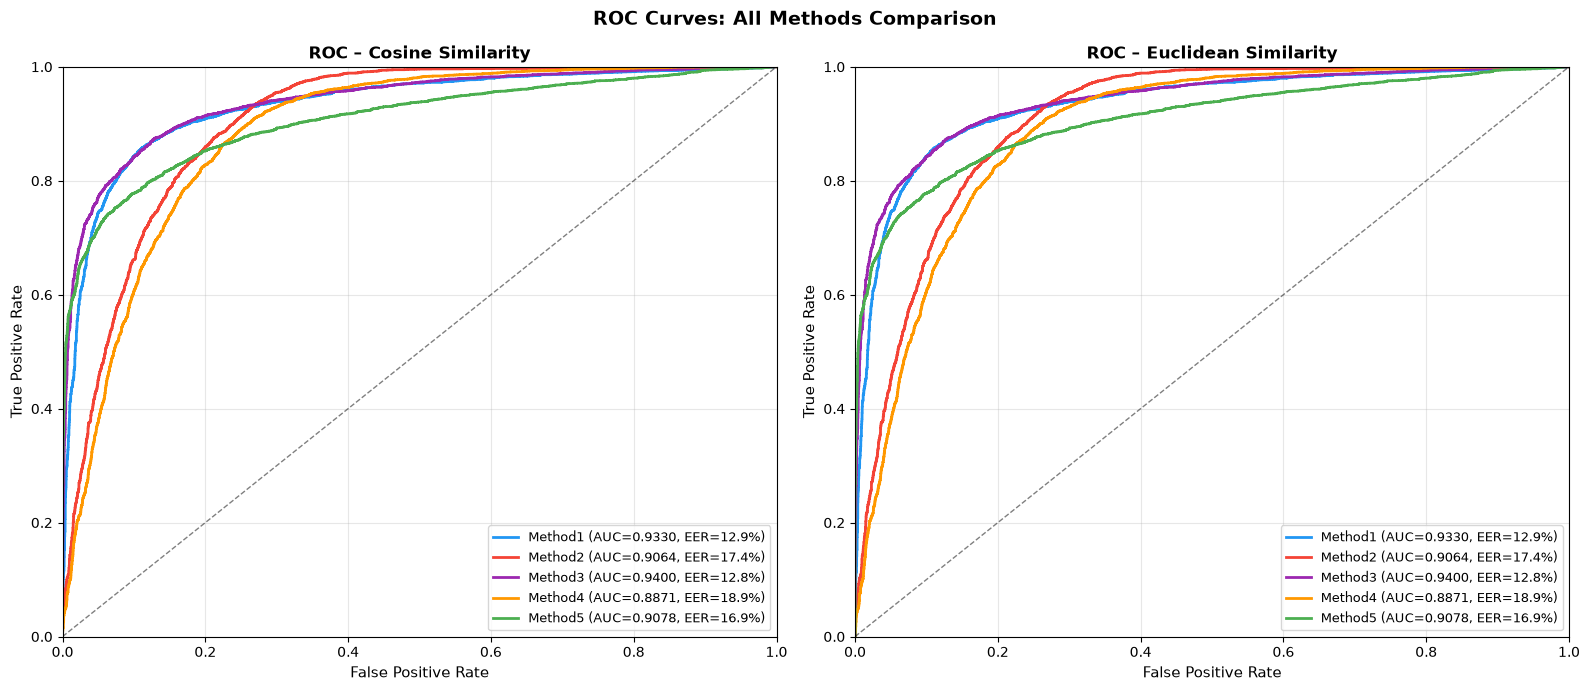

In [12]:
PALETTE = {
    'Method1': ('#2196F3', '#1565C0'),   # blue
    'Method2': ('#F44336', '#B71C1C'),   # red
    'Method3': ('#9C27B0', '#4A148C'),   # purple
    'Method4': ('#FF9800', '#E65100'),   # orange
    'Method5': ('#4CAF50', '#1B5E20'),   # green
}

fig, axes = plt.subplots(1, 2, figsize=(16, 7))

for ax, dist in zip(axes, ['Cosine', 'Euclidean']):
    for name in LOADED.keys():
        key = f'{name} + {dist}'
        if key not in RESULTS: continue
        res = RESULTS[key]
        c = PALETTE.get(name, ('#555', '#333'))[0]
        ax.plot(res['fpr'], res['tpr'], color=c, lw=2,
                label=f"{name} (AUC={res['auc']:.4f}, EER={res['eer']*100:.1f}%)")
    ax.plot([0,1],[0,1],'k--',lw=1,alpha=0.5)
    ax.set_xlabel('False Positive Rate', fontsize=11)
    ax.set_ylabel('True Positive Rate', fontsize=11)
    ax.set_title(f'ROC – {dist} Similarity', fontsize=12, fontweight='bold')
    ax.legend(loc='lower right', fontsize=9)
    ax.grid(alpha=0.3)
    ax.set_xlim(0,1); ax.set_ylim(0,1)

plt.suptitle('ROC Curves: All Methods Comparison', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig(OUT_DIR / 'roc_comparison.png', dpi=150, bbox_inches='tight')
plt.show()

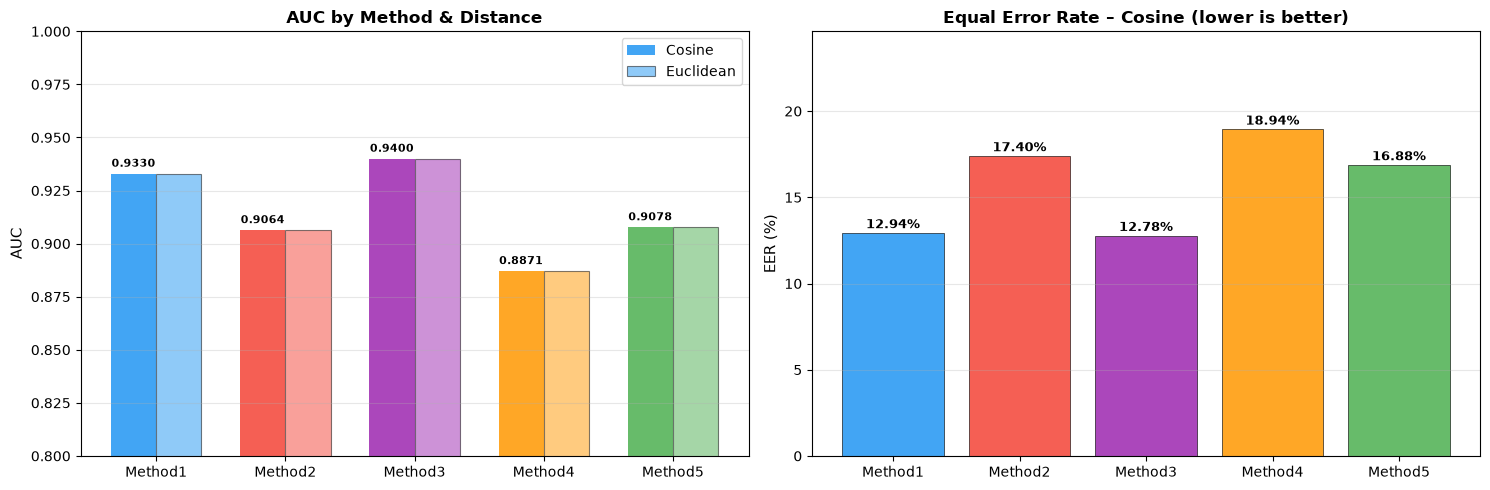

In [13]:
methods = list(LOADED.keys())
auc_cos = [RESULTS[f'{m} + Cosine']['auc']    for m in methods if f'{m} + Cosine' in RESULTS]
auc_euc = [RESULTS[f'{m} + Euclidean']['auc'] for m in methods if f'{m} + Euclidean' in RESULTS]
eer_cos = [RESULTS[f'{m} + Cosine']['eer']*100    for m in methods if f'{m} + Cosine' in RESULTS]

x = np.arange(len(methods)); w = 0.35
colors_list = [PALETTE.get(m, ('#555','#333'))[0] for m in methods]

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# AUC
ax = axes[0]
bars1 = ax.bar(x - w/2, auc_cos, w, label='Cosine',    color=colors_list, alpha=0.85)
bars2 = ax.bar(x + w/2, auc_euc, w, label='Euclidean', color=colors_list, alpha=0.5,
               edgecolor='black', linewidth=0.8)
ax.set_ylabel('AUC', fontsize=11)
ax.set_title('AUC by Method & Distance', fontsize=12, fontweight='bold')
ax.set_xticks(x); ax.set_xticklabels(methods, fontsize=10)
ax.set_ylim(0.8, 1.0); ax.legend(); ax.grid(axis='y', alpha=0.3)
for bar in bars1:
    ax.text(bar.get_x()+bar.get_width()/2, bar.get_height()+0.002,
            f'{bar.get_height():.4f}', ha='center', va='bottom', fontsize=8, fontweight='bold')

# EER
ax = axes[1]
bars = ax.bar(methods, eer_cos, color=colors_list, alpha=0.85, edgecolor='black', linewidth=0.5)
ax.set_ylabel('EER (%)', fontsize=11)
ax.set_title('Equal Error Rate – Cosine (lower is better)', fontsize=12, fontweight='bold')
ax.set_ylim(0, max(eer_cos)*1.3); ax.grid(axis='y', alpha=0.3)
for bar, val in zip(bars, eer_cos):
    ax.text(bar.get_x()+bar.get_width()/2, bar.get_height()+0.1,
            f'{val:.2f}%', ha='center', va='bottom', fontsize=9, fontweight='bold')

plt.tight_layout()
plt.savefig(OUT_DIR / 'auc_eer_bars.png', dpi=150, bbox_inches='tight')
plt.show()

In [14]:
BEST = max(RESULTS, key=lambda k: RESULTS[k]['auc'])

print('=' * 78)
print(f'  {"Method":<33} {"AUC":>7}  {"EER":>7}  {"Best Acc":>9}  {"Threshold":>10}')
print('-' * 78)
for k, v in sorted(RESULTS.items(), key=lambda x: -x[1]['auc']):
    mark = ' ✓ BEST' if k == BEST else ''
    print(f'  {k:<33} {v["auc"]:>7.4f}  {v["eer"]*100:>6.2f}%  '
          f'{v["acc"]*100:>8.2f}%  {v["thresh"]:>10.4f}{mark}')
print('=' * 78)
print(f'\n  Best: {BEST}  (AUC={RESULTS[BEST]["auc"]:.4f})')

  Method                                AUC      EER   Best Acc   Threshold
------------------------------------------------------------------------------
  Method3 + Euclidean                0.9400   12.78%     87.29%     -1.2946 ✓ BEST
  Method3 + Cosine                   0.9400   12.78%     87.29%      0.1620
  Method1 + Cosine                   0.9330   12.94%     87.36%      0.2094
  Method1 + Euclidean                0.9330   12.94%     87.36%     -1.2575
  Method5 + Euclidean                0.9078   16.88%     84.11%     -1.3408
  Method5 + Cosine                   0.9078   16.88%     84.11%      0.1011
  Method2 + Euclidean                0.9064   17.40%     83.03%     -0.9663
  Method2 + Cosine                   0.9064   17.40%     83.03%      0.5331
  Method4 + Cosine                   0.8871   18.94%     81.89%      0.3498
  Method4 + Euclidean                0.8871   18.94%     81.89%     -1.1403

  Best: Method3 + Euclidean  (AUC=0.9400)


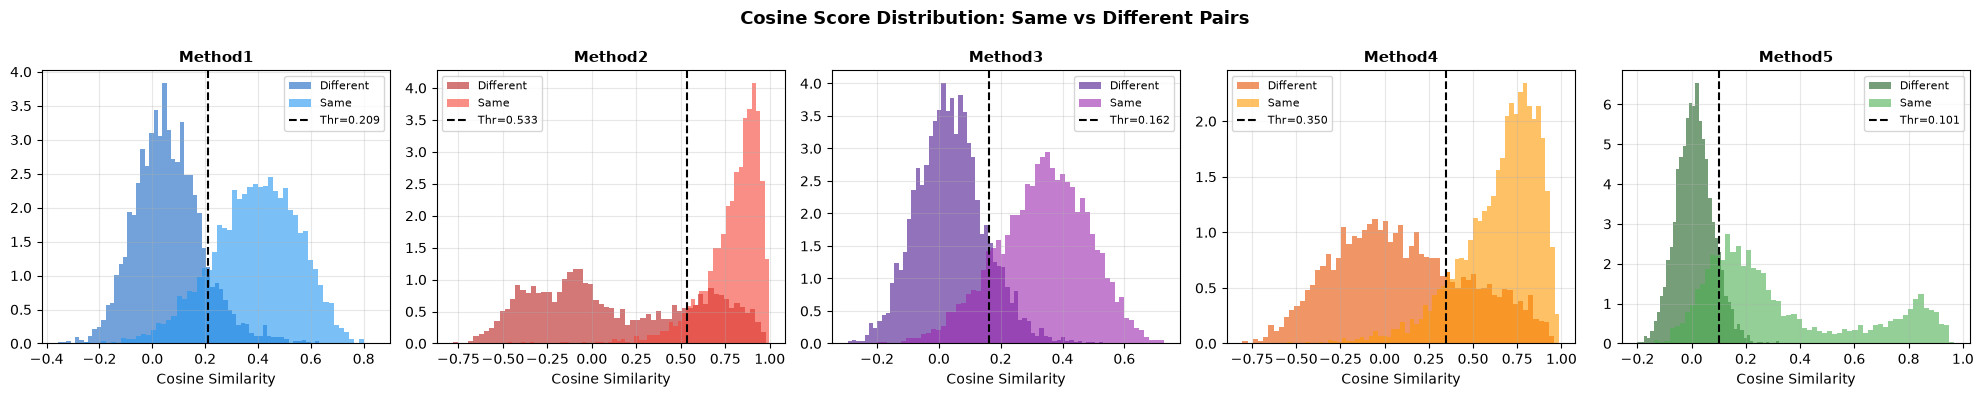

In [15]:
fig, axes = plt.subplots(1, len(EMB_DATA), figsize=(4*len(EMB_DATA), 4), sharey=False)
if len(EMB_DATA) == 1: axes = [axes]

for ax, (name, (e1, e2, lbl)) in zip(axes, EMB_DATA.items()):
    scores = cosine_sim(e1, e2)
    same   = scores[lbl == 1]
    diff   = scores[lbl == 0]
    ax.hist(diff, bins=60, alpha=0.6, color=PALETTE.get(name,('#888','#666'))[1],
            density=True, label='Different')
    ax.hist(same, bins=60, alpha=0.6, color=PALETTE.get(name,('#888','#666'))[0],
            density=True, label='Same')
    thr = RESULTS[f'{name} + Cosine']['thresh']
    ax.axvline(thr, color='black', lw=1.5, linestyle='--', label=f'Thr={thr:.3f}')
    ax.set_title(name, fontsize=11, fontweight='bold')
    ax.set_xlabel('Cosine Similarity'); ax.legend(fontsize=8); ax.grid(alpha=0.3)

plt.suptitle('Cosine Score Distribution: Same vs Different Pairs', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig(OUT_DIR / 'score_distributions.png', dpi=150, bbox_inches='tight')
plt.show()

t-SNE Method1...


/Users/macos/Documents/Swinburne/COS30082/Final/.venv/lib/python3.12/site-packages/threadpoolctl.py:1226: RuntimeWarning: 
Found Intel OpenMP ('libiomp') and LLVM OpenMP ('libomp') loaded at
the same time. Both libraries are known to be incompatible and this
can cause random crashes or deadlocks on Linux when loaded in the
same Python program.
Using threadpoolctl may cause crashes or deadlocks. For more
information and possible workarounds, please see
    https://github.com/joblib/threadpoolctl/blob/master/multiple_openmp.md

  warnings.warn(msg, RuntimeWarning)


t-SNE Method2...
t-SNE Method3...
t-SNE Method4...
t-SNE Method5...


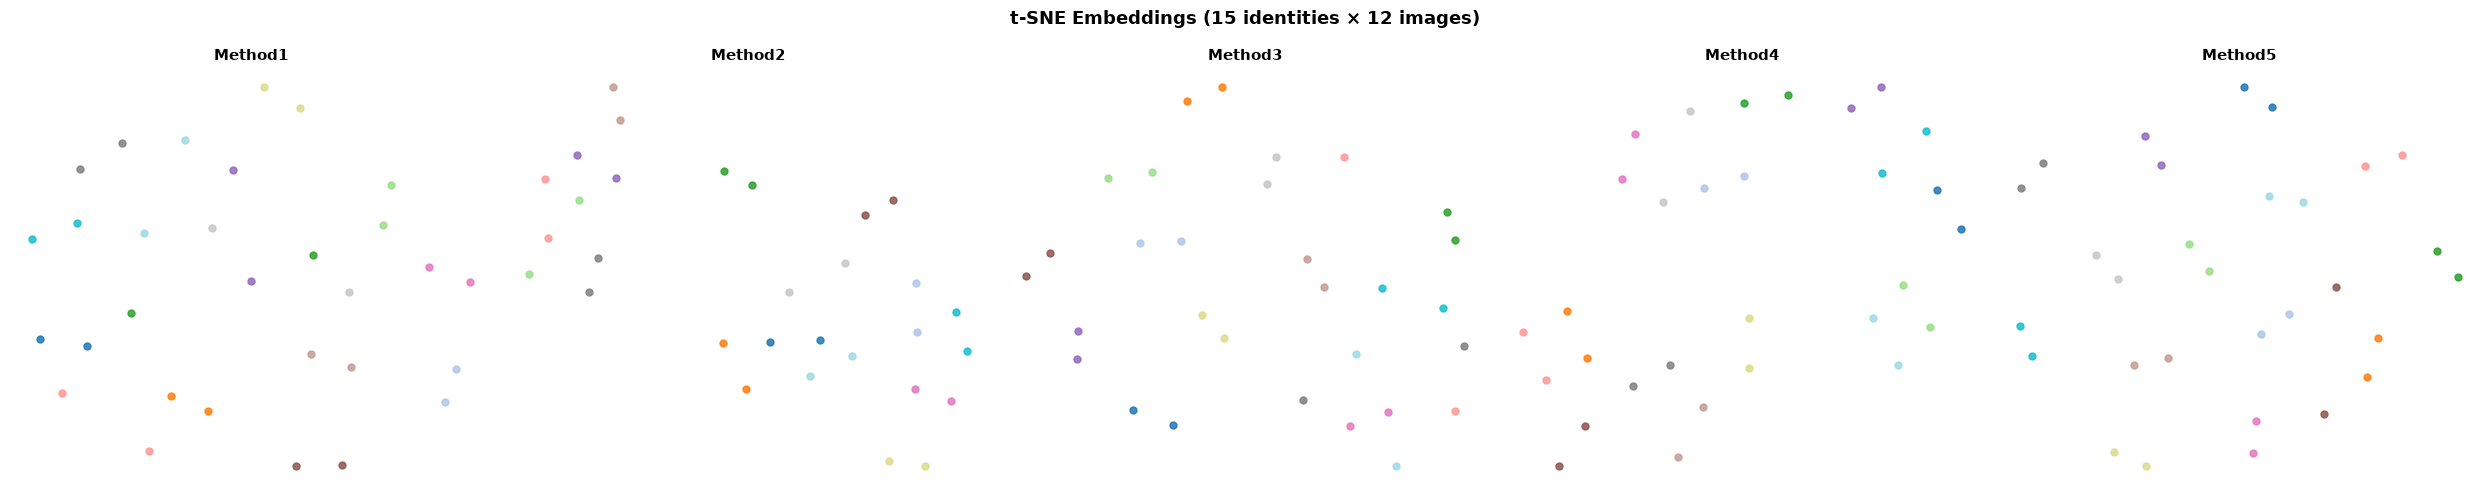

In [18]:
from sklearn.manifold import TSNE

N_IDS    = 15
N_PER_ID = 12

@torch.no_grad()
def get_class_embeddings(model, n_ids=N_IDS, n_per_id=N_PER_ID, transform=None):
    model.eval()
    id_dirs = random.sample([d for d in VAL_DIR.iterdir() if d.is_dir()], n_ids)
    embs, lbls = [], []
    for lbl, d in enumerate(id_dirs):
        for p in list(d.glob('*.jpg'))[:n_per_id]:
            img = Image.open(p).convert('RGB')
            if transform: img = transform(img)
            e = model.get_embedding(img.unsqueeze(0).to(DEVICE)).cpu().numpy().squeeze()
            embs.append(e); lbls.append(lbl)
    return np.array(embs), np.array(lbls)

fig, axes = plt.subplots(1, len(LOADED), figsize=(5*len(LOADED), 5))
if len(LOADED) == 1: axes = [axes]
cmap = plt.cm.tab20(np.linspace(0, 1, N_IDS))

for ax, (name, (model, _)) in zip(axes, LOADED.items()):
    tf = val_transform_vit if name == 'Method5' else val_transform
    print(f't-SNE {name}...')
    embs, lbls = get_class_embeddings(model, transform=tf)
    xy = TSNE(n_components=2, perplexity=12, random_state=SEED, max_iter=1000).fit_transform(embs)
    for i in range(N_IDS):
        m = lbls == i
        ax.scatter(xy[m,0], xy[m,1], color=cmap[i], s=25, alpha=0.85)
    ax.set_title(name, fontsize=11, fontweight='bold')
    ax.axis('off')

plt.suptitle(f't-SNE Embeddings ({N_IDS} identities × {N_PER_ID} images)', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig(OUT_DIR / 'tsne_all_methods.png', dpi=130, bbox_inches='tight')
plt.show()

In [19]:
print('=' * 55)
print('  FINAL COMPARISON SUMMARY')
print('=' * 55)
# Best per method (take max of cosine/euclidean)
for name in LOADED.keys():
    best_auc = max(RESULTS.get(f'{name} + Cosine',    {}).get('auc', 0),
                   RESULTS.get(f'{name} + Euclidean', {}).get('auc', 0))
    best_dist = 'Cosine' if (RESULTS.get(f'{name} + Cosine',{}).get('auc',0) >=
                              RESULTS.get(f'{name} + Euclidean',{}).get('auc',0)) else 'Euclidean'
    eer = RESULTS[f'{name} + {best_dist}']['eer'] * 100
    print(f'  {name} ({best_dist:>10}): AUC={best_auc:.4f}  EER={eer:.2f}%')
print('=' * 55)
print(f'  Best overall: {BEST}')
print(f'               AUC = {RESULTS[BEST]["auc"]:.4f}')
print(f'               EER = {RESULTS[BEST]["eer"]*100:.2f}%')
print('=' * 55)
print(f'  Charts saved to: {OUT_DIR}')

  FINAL COMPARISON SUMMARY
  Method1 (    Cosine): AUC=0.9330  EER=12.94%
  Method2 ( Euclidean): AUC=0.9064  EER=17.40%
  Method3 ( Euclidean): AUC=0.9400  EER=12.78%
  Method4 (    Cosine): AUC=0.8871  EER=18.94%
  Method5 ( Euclidean): AUC=0.9078  EER=16.88%
  Best overall: Method3 + Euclidean
               AUC = 0.9400
               EER = 12.78%
  Charts saved to: comparison
